In [1]:
import sys
import math
import torch
import matplotlib.pyplot as plt

from tqdm import tqdm
from pathlib import Path

In [2]:
codebase_dir = Path.cwd() / "AVQ"
sys.path.insert(0, str(codebase_dir))

In [3]:
from avq.helpers import set_global_seed
from avq.generation.prior import load_prior
from avq.generation.utils import load_autoencoder
from avq.generation.extract import sequence_to_structured_indices
from avq.generation.generate import decode_hard_indices_to_latent
from avq.generation.paths import get_prior_checkpoint, get_autoencoder_checkpoint

In [4]:
TINY_EXPERIMENTS = [
    ("VQ",      "vq_16x16_k1024_d64"),
    ("VQ-EMA",  "vqema_16x16_k1024_d64"),
    ("FSQ",     "fsq_16x16_k1000_d64"),
    ("DiVeQ",   "diveq_16x16_k1024_d64"),
    ("ST-GS",   "stgs_16x16_k1024_d64"),
    ("AVQ",     "avq_16x16_k1024_d64"),
    ("RVQ-EMA", "rvqema_16x16_q3_k1024_d64"),
    ("R-DiVeQ", "rdiveq_16x16_q3_k1024_d64"),
    ("R-STGS",  "rstgs_16x16_q3_k1024_d64"),
    ("ARVQ",    "arvq_16x16_q3_k1024_d64"),
]

MINI_EXPERIMENTS = [
    ("VQ",      "vq_32x32_k1024_d64"),
    ("VQ-EMA",  "vqema_32x32_k1024_d64"),
    ("FSQ",     "fsq_32x32_k1000_d64"),
    ("DiVeQ",   "diveq_32x32_k1024_d64"),
    ("ST-GS",   "stgs_32x32_k1024_d64"),
    ("AVQ",     "avq_32x32_k1024_d64"),
    ("RVQ-EMA", "rvqema_32x32_q3_k1024_d64"),
    ("R-DiVeQ", "rdiveq_32x32_q3_k1024_d64"),
    ("R-STGS",  "rstgs_32x32_q3_k1024_d64"),
    ("ARVQ",    "arvq_32x32_q3_k1024_d64"),
]

# Tiny Imagenet Class IDs
TINY_CLASSES = {
    "Seashore": 198,
    "Pizza": 191,
}

root_dir = "/workspace/project"
dataset = "tiny-imagenet"
model_seed = 42
sampling_seed = 15
num_samples = 8
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [5]:
# Helpers
@torch.inference_mode()
def generate_decode_class(experiment, class_id, num_samples=8):
    # Load autoencoder
    checkpoint_path = get_autoencoder_checkpoint(
        root_dir=root_dir, 
        dataset=dataset, 
        model_seed=model_seed, 
        experiment=experiment,
    )

    model, autoencoder_config, _ = load_autoencoder(
        experiment_name=experiment,
        checkpoint_path=checkpoint_path,
        device=device,
    )

    # Load prior
    prior_checkpoint_path = get_prior_checkpoint(
        root_dir=root_dir,
        dataset=dataset,
        model_seed=model_seed,
        experiment=experiment,
    )

    prior, prior_config, _ = load_prior(
        experiment_name=experiment,
        checkpoint_path=prior_checkpoint_path,
        device=device,
    )

    # Run autoencoder and prior inference
    model.eval()
    prior.eval()

    # Latent size: Tiny ImageNet: 256 -> 16 x 16; MiniPlaces: 1024 -> 32 x 32
    latent_grid = int(math.sqrt(prior_config.sequence_length))
    assert latent_grid * latent_grid == prior_config.sequence_length

    # Prepare class labels for conditioning
    labels = torch.full((num_samples,), fill_value=class_id, dtype=torch.long, device=device)

    # Reset so every method uses same sampling seed
    set_global_seed(sampling_seed)

    # Generate sequence
    generated_sequence = prior.generate(class_labels=labels, temperature=0.9, top_k=None)

    # Decode sequence
    structured_indices = sequence_to_structured_indices(
        sequence=generated_sequence,
        latent_grid=latent_grid,
        num_stages=prior_config.num_codebooks,
    )

    quantized_latent = decode_hard_indices_to_latent(
        model=model,
        method=autoencoder_config.method,
        indices=structured_indices,
    )

    decoded = model.decoder(quantized_latent)
    decoded = decoded.clamp(-1.0, 1.0)

    # Convert decoded output to uint8 image: [B, 3, H, W]
    images = ((decoded + 1.0) * 127.5).round().clamp(0, 255)
    images = images.to(torch.uint8).cpu()

    # Release GPU memory
    del prior
    del model
    torch.cuda.empty_cache()

    return images


def generate_methods_for_class(class_id):
    method_images = {}
    EXPERIMENTS = TINY_EXPERIMENTS if dataset == "tiny-imagenet" else MINI_EXPERIMENTS

    for method, experiment in tqdm(EXPERIMENTS, desc=f"Generating class {class_id}",):
        method_images[method] = generate_decode_class(
            experiment=experiment,
            class_id=class_id,
            num_samples=num_samples,
        )

    return method_images

In [6]:
def plot_class_figure(method_images, class_name, output_path=None, figsize=(8.5, 10.5)):
    EXPERIMENTS = TINY_EXPERIMENTS if dataset == "tiny-imagenet" else MINI_EXPERIMENTS
    
    num_methods = len(EXPERIMENTS)
    fig, axes = plt.subplots(nrows=num_methods, ncols=num_samples, figsize=figsize)

    for row, (method, _) in enumerate(EXPERIMENTS):
        images = method_images[method]

        for col in range(num_samples):
            ax = axes[row, col]
            ax.imshow(images[col].permute(1, 2, 0).numpy(), interpolation="nearest")

            ax.set_xticks([])
            ax.set_yticks([])

            # Remove subplot borders
            for spine in ax.spines.values():
                spine.set_visible(False)

            # Method name on left side
            if col == 0:
                ax.set_ylabel(method, fontsize=9, fontweight="bold", rotation=0, labelpad=32, va="center")

    fig.suptitle(class_name, fontsize=11, fontweight="bold", y=0.995)

    plt.subplots_adjust(
        left=0.12,
        right=0.995,
        top=0.965,
        bottom=0.005,
        wspace=0.03,
        hspace=0.03,
    )

    if output_path is not None:
        plt.savefig(output_path, bbox_inches="tight", pad_inches=0.02)

    plt.show()
    plt.close(fig)

Generating class 198: 100%|██████████| 10/10 [00:14<00:00,  1.45s/it]


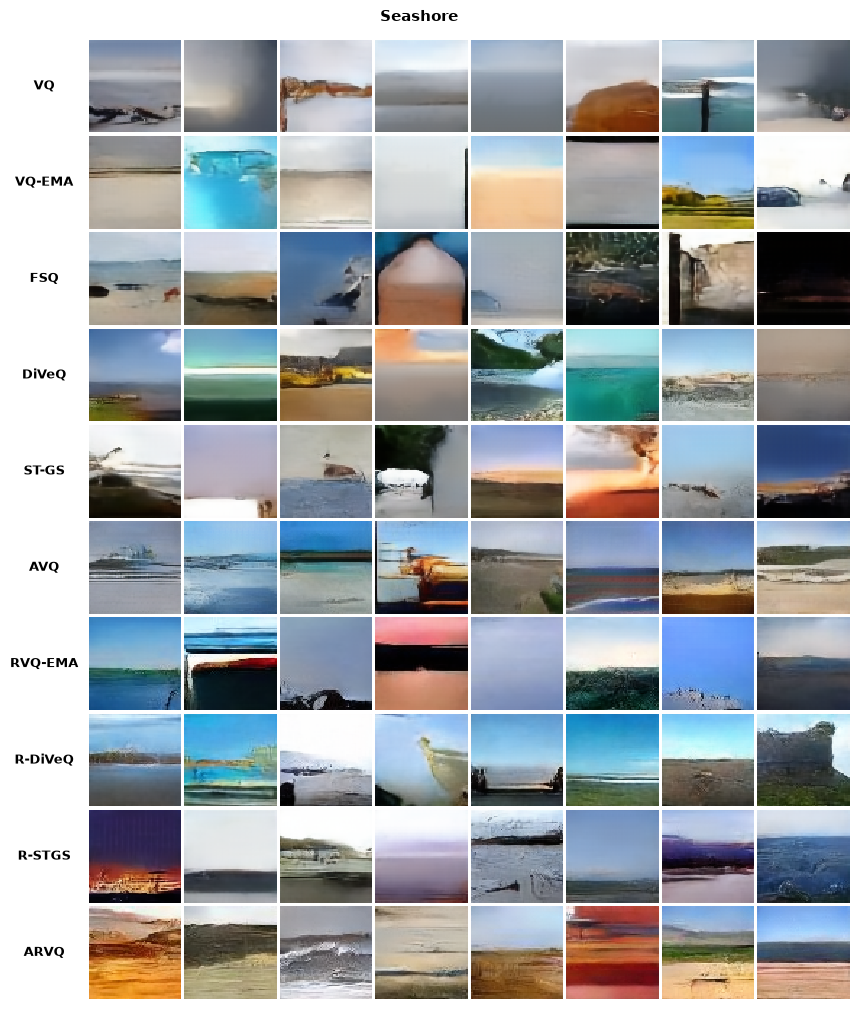

In [7]:
# Seashore figure
seashore_images = generate_methods_for_class(TINY_CLASSES["Seashore"])

plot_class_figure(
    method_images=seashore_images, 
    class_name="Seashore",
    output_path="tiny_imagenet_generation_seashore.pdf",
    figsize=(8.7, 10)
)

Generating class 191: 100%|██████████| 10/10 [00:10<00:00,  1.04s/it]


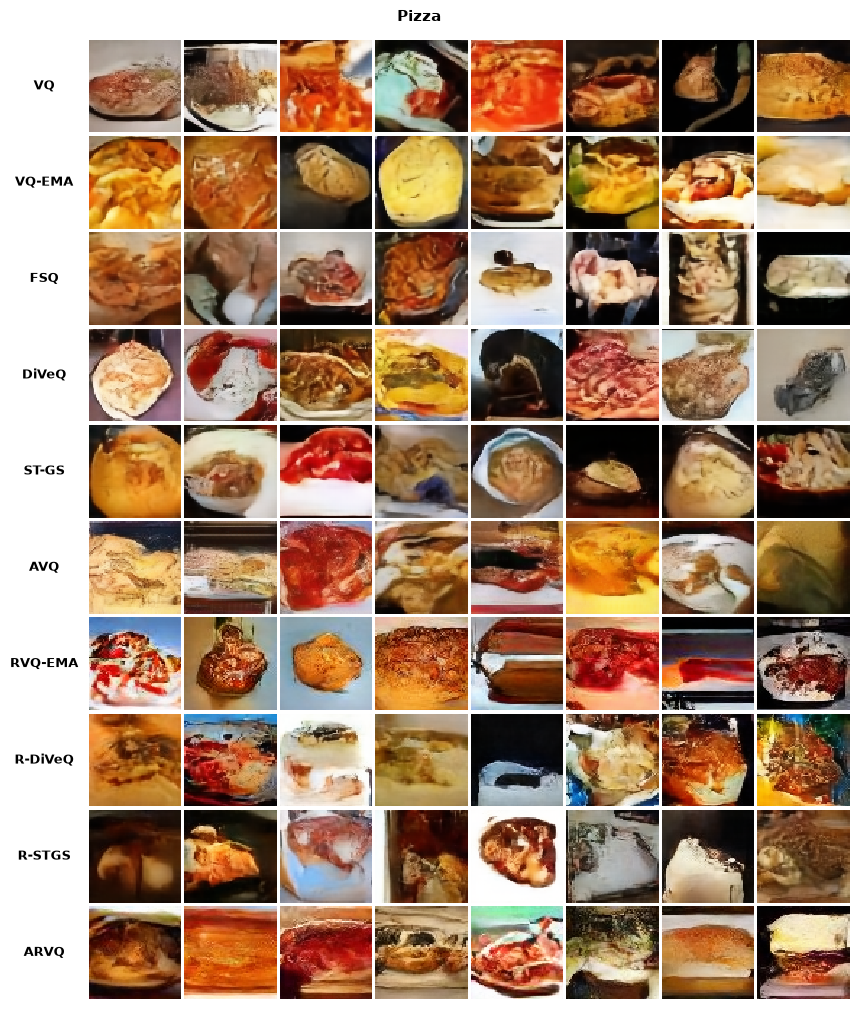

In [8]:
# Pizza figure
pizza_images = generate_methods_for_class(TINY_CLASSES["Pizza"])

plot_class_figure(
    method_images=pizza_images,
    class_name="Pizza",
    output_path="tiny_imagenet_generation_pizza.pdf",
    figsize=(8.7, 10)
)